# **Bank Term Deposit Subscription Prediction Using an End-to-End Machine Learning Pipeline**

# Importing the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the dataset

In [2]:
df = pd.read_csv("bank.csv", sep=";")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


# Understanding the Dataset

## Checking the dimension

In [3]:
df.shape

(4521, 17)

## Checking the properties

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


## Checking the summary statistics

In [5]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


## Checking for missing values

In [6]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

# Assessing the data quality

## Checking for duplicate records

In [7]:
df.duplicated().sum()

np.int64(0)

## Checking for unknown values

In [8]:
# Selecting categorical columns
categorical_columns = df.select_dtypes(include='object').columns

In [9]:
# Counting 'unknown' entries in each categorical column
(df[categorical_columns] == 'unknown').sum()

job            38
marital         0
education     187
default         0
housing         0
loan            0
contact      1324
month           0
poutcome     3705
y               0
dtype: int64

# Examining the target variable

In [10]:
# Counting customers in each target class
df['y'].value_counts()

y
no     4000
yes     521
Name: count, dtype: int64

In [11]:
# Calculating the percentage distribution of each target class
df['y'].value_counts(normalize=True) * 100

y
no     88.476001
yes    11.523999
Name: proportion, dtype: float64

# Performing exploratory data analysis (EDA)

## Visualizing the distribution of term deposit subscriptions

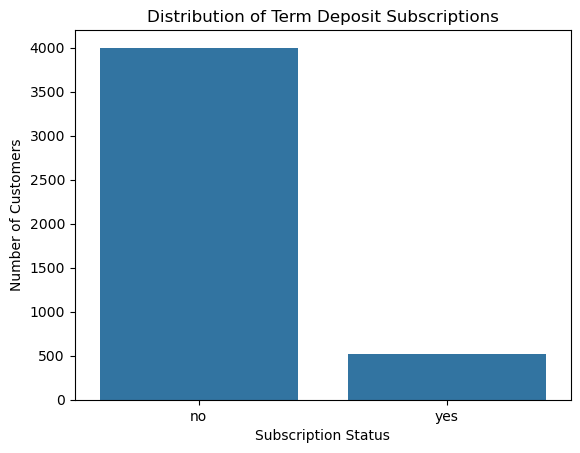

In [12]:
# Visualizing the distribution of the target classes
sns.countplot(data=df, x="y")

plt.title("Distribution of Term Deposit Subscriptions")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")

plt.show()

## Visualizing the distribution of customer ages

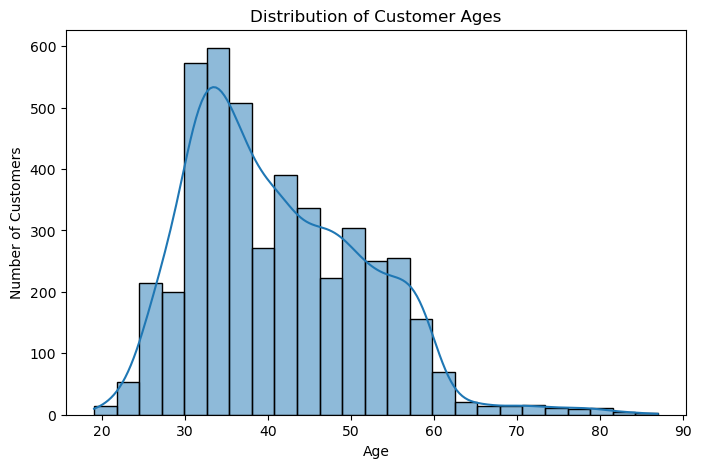

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', bins=25, kde=True)

plt.title('Distribution of Customer Ages')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

## Visualizing account balance by subscription status

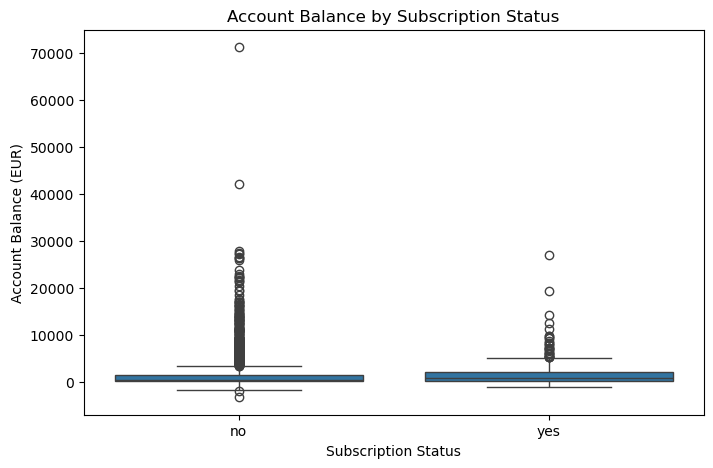

In [14]:
# Comparing account balances across subscription categories
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='y', y='balance')

plt.title('Account Balance by Subscription Status')
plt.xlabel('Subscription Status')
plt.ylabel('Account Balance (EUR)')

plt.show()

# Preprocessing the data

## Separating the features and target variable

In [15]:
# Separating the features from the target variable
X = df.drop(columns=['y', 'duration'])
y = df['y'].map({'no': 0, 'yes': 1})

In [16]:
# Checking the dimensions of the features and target
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (4521, 15)
Target shape: (4521,)


In [17]:
# Verifying the target encoding
print("\nTarget distribution:")
print(y.value_counts())


Target distribution:
y
0    4000
1     521
Name: count, dtype: int64


## Splitting the Dataset

In [18]:
# Importing train_test_split
from sklearn.model_selection import train_test_split

In [19]:
# Splitting the dataset while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [20]:
# Verifying the resulting dataset dimensions
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3616, 15)
X_test: (905, 15)
y_train: (3616,)
y_test: (905,)


In [21]:
# Checking class proportions in both subsets
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))


Training class distribution:
y
0    0.884679
1    0.115321
Name: proportion, dtype: float64


## Understanding underlying features before applying feature engineering

### Examining previous contact history

In [22]:
# Counting customers with and without previous contact history
print("Previous contact history:")
print((X_train['pdays'] == -1).value_counts())

Previous contact history:
pdays
True     2947
False     669
Name: count, dtype: int64


In [23]:
# Examineing previous campaign contact counts
print("\nPrevious campaign contacts:")
print(X_train['previous'].value_counts().head(10))


Previous campaign contacts:
previous
0    2947
1     227
2     167
3      97
4      63
5      38
7      21
6      19
8      15
9       6
Name: count, dtype: int64


### Checking previous contact consistency

In [24]:
# Comparing previous contact history with campaign contact counts
pd.crosstab(
    X_train['pdays'] == -1,
    X_train['previous'] == 0
)

previous,False,True
pdays,,
False,669,0
True,0,2947


## Building the preprocessing pipeline

### Creating a custom feature engineering transformer

In [25]:
# Importing FunctionTransformer
from sklearn.preprocessing import FunctionTransformer

In [26]:
# Defining a function for engineering previous contact features
def engineer_contact_features(data):
    data = data.copy()

    # Creating an indicator for previous contact history
    data['previously_contacted'] = (data['previous'] > 0).astype(int)

    # Replacing the special -1 value with 0
    data['pdays'] = data['pdays'].replace(-1, 0)

    return data

In [27]:
# Creating a reusable feature engineering transformer
feature_engineer = FunctionTransformer(engineer_contact_features, validate=False)

### Testing the feature engineering transformer

In [28]:
# Applying feature engineering to the first five training records
sample_transformed = feature_engineer.transform(X_train.head())

In [29]:
# Displaying the relevant columns
sample_transformed[['previous', 'pdays', 'previously_contacted']]

,previous,pdays,previously_contacted
2236,0,0,0
858,19,85,1
3531,0,0,0
2737,0,0,0
1257,0,0,0


## Identifying numerical and categorical features

In [30]:
# Identifying numerical and categorical features
numerical_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

In [31]:
# Including the newly engineered numerical feature
numerical_features.append('previously_contacted')

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## Defining numerical and categorical preprocessing

In [32]:
# Importing the preprocessing functions
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [33]:
# Creating preprocessing steps for numerical features
numerical_transformer = Pipeline(steps=[('scaler', StandardScaler())])

In [34]:
# Creating preprocessing steps for categorical features
categorical_transformer = Pipeline(steps=[('encoder', OneHotEncoder(handle_unknown='ignore'))])

In [35]:
# Combining numerical and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

## Combining feature engineering and preprocessing

In [36]:
# Combining feature engineering and preprocessing
preprocessing_pipeline = Pipeline(steps=[
    ('feature_engineering', feature_engineer),
    ('preprocessing', preprocessor)
])

In [37]:
# Displaying the pipeline structure
preprocessing_pipeline

,steps,"[('feature_engineering', ...), ('preprocessing', ...)]"
,transform_input,None
,memory,None
,verbose,False
,func,<function eng...00188EA909F80>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,None
,kw_args,None


# Building the machine learning models

## Importing the classification algorithms

In [39]:
# Importing the classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [40]:
# Importing clone to create independent preprocessing pipelines
from sklearn.base import clone

## Creating the logistic regression pipeline

In [41]:
# Combining preprocessing with Logistic Regression
logistic_pipeline = Pipeline(steps=[
    ('preprocessing', clone(preprocessing_pipeline)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

In [42]:
# Displaying the Logistic Regression pipeline
logistic_pipeline

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('feature_engineering', ...), ('preprocessing', ...)]"
,transform_input,None
,memory,None
,verbose,False
,func,<function eng...00188EA909F80>
,inverse_func,None
,validate,False


## Creating the random forest pipeline

In [43]:
# Combining preprocessing with Random Forest
random_forest_pipeline = Pipeline(steps=[
    ('preprocessing', clone(preprocessing_pipeline)),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=2))
])

In [44]:
# Displaying the Random Forest pipeline
random_forest_pipeline

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('feature_engineering', ...), ('preprocessing', ...)]"
,transform_input,None
,memory,None
,verbose,False
,func,<function eng...00188EA909F80>
,inverse_func,None
,validate,False


## Training the machine learning models

### Training logistic regression

In [45]:
# Training the logistic regression pipeline
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed successfully.")

Logistic Regression training completed successfully.


### Training random forest

In [46]:
# Training the random forest pipeline
random_forest_pipeline.fit(X_train, y_train)

print("Random Forest training completed successfully.")

Random Forest training completed successfully.


### Verifying model training

In [47]:
# Importing the 'check_is_fitted' verification function
from sklearn.utils.validation import check_is_fitted

In [48]:
# Verifying both trained pipelines
check_is_fitted(logistic_pipeline)
check_is_fitted(random_forest_pipeline)

print("Both machine learning pipelines are successfully fitted.")

Both machine learning pipelines are successfully fitted.


## Comparing model performance using cross-validation

### Importing cross-validation functions

In [49]:
# Importing functions for cross-validation
from sklearn.model_selection import StratifiedKFold, cross_validate

### Defining the cross-validation strategy

In [50]:
# Creating a stratified 5-fold cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [51]:
# Defining the evaluation metrics
scoring = ['accuracy', 'precision', 'recall', 'f1']

### Cross-validating logistic regression

In [52]:
# Evaluating logistic regression using cross-validation
logistic_cv = cross_validate(logistic_pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)

In [53]:
# Displaying the average evaluation scores
for metric in scoring:
    print(f"{metric.capitalize()}: {logistic_cv['test_' + metric].mean():.4f}")

Accuracy: 0.8905
Precision: 0.5998
Recall: 0.1488
F1: 0.2367


### Cross-validating random forest

In [54]:
# Evaluating random forest using cross-validation
rf_cv = cross_validate(random_forest_pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)

In [55]:
# Displaying the average evaluation scores
for metric in scoring:
    print(f"{metric.capitalize()}: {rf_cv['test_' + metric].mean():.4f}")

Accuracy: 0.8905
Precision: 0.6217
Recall: 0.1392
F1: 0.2257


### Comparing cross-validation results

In [56]:
# Creating a comparison table for both models
cv_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Logistic Regression': [logistic_cv['test_' + metric].mean() for metric in scoring],
    'Random Forest': [rf_cv['test_' + metric].mean() for metric in scoring]
})

In [57]:
# Displaying the comparison table
cv_results.round(4)

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.8905,0.8905
1,Precision,0.5998,0.6217
2,Recall,0.1488,0.1392
3,F1-score,0.2367,0.2257


# Performing hyperparameter tuning

## Importing GridSearchCV

In [58]:
# Importing GridSearchCV for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

## Tuning the logistic regression model

### Defining the logistic regression parameter grid

In [59]:
# Defining hyperparameters for logistic regression
logistic_param_grid = {
    'classifier__C': [0.1, 1, 10],
    'classifier__class_weight': [None, 'balanced']
}

### Tuning logistic regression using GridSearchCV

In [60]:
# Creating the hyperparameter search
logistic_grid = GridSearchCV(estimator=logistic_pipeline, param_grid=logistic_param_grid, scoring='f1', cv=cv, n_jobs=1)

In [61]:
# Fitting the search on the training dataset
logistic_grid.fit(X_train, y_train)

print("Hyperparameter tuning completed successfully.")

Hyperparameter tuning completed successfully.


### Examining the best logistic regression parameters

In [62]:
# Displaying the best hyperparameters and cross-validation F1-score
print("Best parameters:", logistic_grid.best_params_)
print("Best cross-validation F1-score:", round(logistic_grid.best_score_, 4))

Best parameters: {'classifier__C': 10, 'classifier__class_weight': 'balanced'}
Best cross-validation F1-score: 0.3223


### Selecting the best logistic regression pipeline

In [63]:
# Selecting the best fitted logistic regression pipeline
best_logistic_pipeline = logistic_grid.best_estimator_

In [64]:
# Verifying that the selected pipeline is fitted
check_is_fitted(best_logistic_pipeline)

print("Best Logistic Regression pipeline selected successfully.")

Best Logistic Regression pipeline selected successfully.


## Tuning the random forest model

### Defining the random forest parameter grid

In [65]:
# Defining hyperparameters for random forest
rf_param_grid = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [5, 10],
    'classifier__class_weight': [None, 'balanced']
}

### Tuning random forest using GridSearchCV

In [66]:
# Creating the hyperparameter search
rf_grid = GridSearchCV(estimator=random_forest_pipeline, param_grid=rf_param_grid, scoring='f1', cv=cv, n_jobs=1)

In [67]:
# Fitting the search on the training dataset
rf_grid.fit(X_train, y_train)

print("Random Forest hyperparameter tuning completed successfully.")

Random Forest hyperparameter tuning completed successfully.


### Examining the best random forest parameters

In [68]:
# Displaying the best hyperparameters and cross-validation F1-score
print("Best parameters:", rf_grid.best_params_)
print("Best cross-validation F1-score:", round(rf_grid.best_score_, 4))

Best parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 5, 'classifier__n_estimators': 100}
Best cross-validation F1-score: 0.3434


### Selecting the best random forest pipeline

In [69]:
# Selecting the best fitted random forest pipeline
best_rf_pipeline = rf_grid.best_estimator_

In [70]:
# Verifying that the selected pipeline is fitted
check_is_fitted(best_rf_pipeline)

print("Best Random Forest pipeline selected successfully.")

Best Random Forest pipeline selected successfully.


## Comparing the tuned machine learning models

### Creating a comparison table of tuned model performance

In [71]:
# Comparing the best cross-validation F1-scores
tuned_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Original F1-score': [logistic_cv['test_f1'].mean(), rf_cv['test_f1'].mean()],
    'Tuned F1-score': [logistic_grid.best_score_, rf_grid.best_score_]
})

In [72]:
# Displaying the comparison table
tuned_results.round(4)

,Model,Original F1-score,Tuned F1-score
0,Logistic Regression,0.2367,0.3223
1,Random Forest,0.2257,0.3434


### Visualizing the improvement in model performance

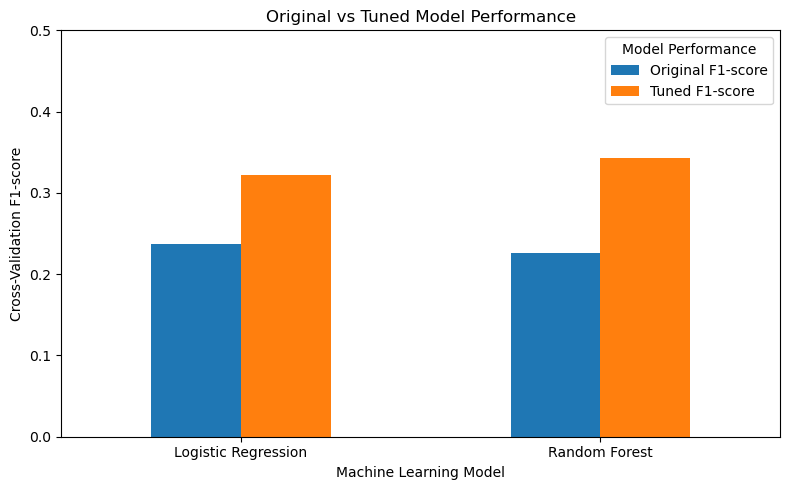

In [73]:
# Comparing original and tuned F1-scores visually
tuned_results.set_index('Model')[['Original F1-score', 'Tuned F1-score']].plot(kind='bar', figsize=(8, 5))

plt.title('Original vs Tuned Model Performance')
plt.xlabel('Machine Learning Model')
plt.ylabel('Cross-Validation F1-score')
plt.xticks(rotation=0)
plt.ylim(0, 0.5)
plt.legend(title='Model Performance')
plt.tight_layout()

plt.show()

## Selecting the best-performing tuned model

In [74]:
# Selecting the model with the highest tuned F1-score
best_model_name = tuned_results.loc[tuned_results['Tuned F1-score'].idxmax(), 'Model']

In [75]:
# Assigning the corresponding fitted pipeline
if best_model_name == 'Logistic Regression':
    final_pipeline = best_logistic_pipeline
else:
    final_pipeline = best_rf_pipeline

print("Selected model:", best_model_name)

Selected model: Random Forest


# Evaluating the selected model on the test dataset

## Generating predictions on the test dataset

In [77]:
# Generating predictions using the selected Random Forest pipeline
y_pred = final_pipeline.predict(X_test)

In [78]:
# Checking the distribution of predicted classes
print("Predicted class distribution:")
print(pd.Series(y_pred).value_counts())

Predicted class distribution:
0    686
1    219
Name: count, dtype: int64


## Calculating classification performance metrics

In [79]:
# Importing classification evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

In [80]:
# Evaluating the selected model on the test dataset
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Subscription', 'Subscription'], zero_division=0))

Accuracy: 0.7757
Precision: 0.274
Recall: 0.5769
F1-score: 0.3715

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.94      0.80      0.86       801
   Subscription       0.27      0.58      0.37       104

       accuracy                           0.78       905
      macro avg       0.60      0.69      0.62       905
   weighted avg       0.86      0.78      0.81       905



## Visualizing the confusion matrix

In [81]:
# Importing confusion matrix functions
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

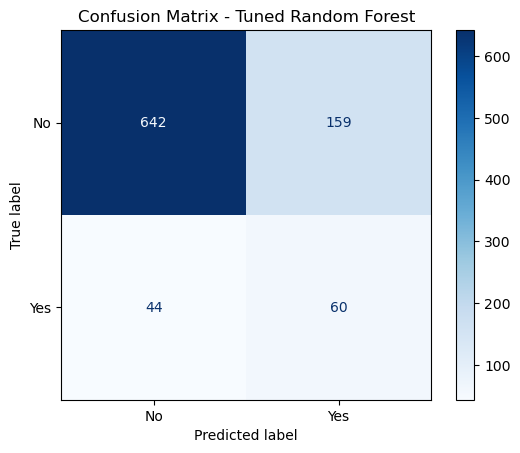

In [82]:
# Calculating and displaying the confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])

disp.plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix - Tuned Random Forest')
plt.show()

## Calculating the ROC-AUC score

In [83]:
# Importing ROC-AUC evaluation function
from sklearn.metrics import roc_auc_score

In [84]:
# Generating predicted probabilities for the positive class
y_prob = final_pipeline.predict_proba(X_test)[:, 1]

In [85]:
# Calculating ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.7442


## Visualizing the ROC curve

In [86]:
# Importing ROC curve visualization
from sklearn.metrics import RocCurveDisplay

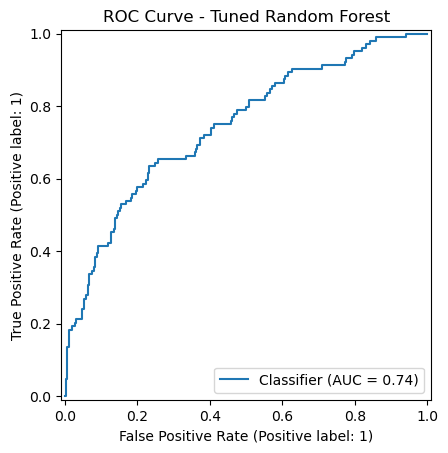

In [87]:
# Plotting the ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title('ROC Curve - Tuned Random Forest')
plt.show()

## Visualizing the precision-recall curve

In [88]:
# Importing precision-recall curve visualization
from sklearn.metrics import PrecisionRecallDisplay

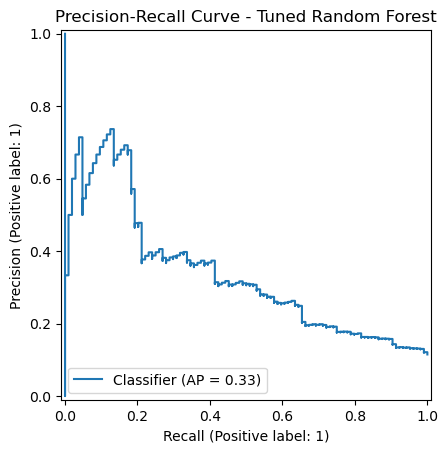

In [89]:
# Plotting the precision-recall curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob)

plt.title('Precision-Recall Curve - Tuned Random Forest')
plt.show()

# Saving and testing the machine learning pipeline

## Saving the trained random forest pipeline

In [90]:
# Importing joblib for saving and loading the trained pipeline
import joblib

In [91]:
# Saving the complete trained random forest pipeline
model_filename = 'bank_marketing_pipeline.pkl'

joblib.dump(final_pipeline, model_filename)

print("Trained machine learning pipeline saved successfully.")

Trained machine learning pipeline saved successfully.


## Loading the saved machine learning pipeline

In [92]:
# Loading the previously saved Random Forest pipeline
loaded_pipeline = joblib.load(model_filename)

print("Saved machine learning pipeline loaded successfully.")

Saved machine learning pipeline loaded successfully.


In [93]:
# Confirming that the loaded pipeline is fitted
check_is_fitted(loaded_pipeline)

print("The loaded machine learning pipeline is successfully fitted.")

The loaded machine learning pipeline is successfully fitted.


## Verifying prediction consistency

In [94]:
# Importing NumPy for comparing model predictions
import numpy as np

In [95]:
# Generating predictions using the loaded pipeline
loaded_predictions = loaded_pipeline.predict(X_test)

In [96]:
# Comparing predictions from the original and loaded pipelines
predictions_match = np.array_equal(y_pred, loaded_predictions)

print("Predictions are identical:", predictions_match)

Predictions are identical: True


## Testing predictions on individual customer records

In [97]:
# Selecting five customer records from the test dataset
sample_customers = X_test.head(5)

In [98]:
# Displaying the selected customer records
sample_customers

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
2032,59,management,married,primary,no,1727,no,no,telephone,25,may,4,358,2,failure
943,40,technician,married,secondary,no,109,no,no,unknown,20,jun,22,-1,0,unknown
408,44,management,married,secondary,no,438,yes,no,telephone,8,may,3,303,1,failure
3034,29,services,married,primary,no,-102,no,no,unknown,4,jul,1,-1,0,unknown
3447,53,management,married,tertiary,no,146,no,no,unknown,30,may,1,-1,0,unknown


In [99]:
# Predicting subscription outcomes for the selected customers
sample_predictions = loaded_pipeline.predict(sample_customers)

In [100]:
# Generating subscription probabilities
sample_probabilities = loaded_pipeline.predict_proba(sample_customers)[:, 1]

In [101]:
# Creating a table to compare predictions with actual outcomes
sample_results = pd.DataFrame({
    'Actual Subscription': y_test.loc[sample_customers.index].map({0: 'No', 1: 'Yes'}),
    'Predicted Subscription': pd.Series(sample_predictions, index=sample_customers.index).map({0: 'No', 1: 'Yes'}),
    'Subscription Probability (%)': (sample_probabilities * 100).round(2)
})

In [102]:
# Displaying the prediction results
sample_results

,Actual Subscription,Predicted Subscription,Subscription Probability (%)
2032,Yes,Yes,52.99
943,No,No,27.54
408,No,No,40.24
3034,No,No,30.40
3447,No,No,31.26


## Results and Findings

In this project, I developed a machine learning pipeline to predict whether a bank customer would subscribe to a term deposit. I trained and compared two classification models, Logistic Regression and Random Forest, using the Bank Marketing dataset.

The dataset contained 4,521 customer records. I removed the `duration` column to avoid using information that would not be available before a marketing call. I also converted the target variable into numerical values, where 0 represented customers who did not subscribe and 1 represented those who subscribed.

Out of the 4,521 customers, 4,000 did not subscribe, while 521 subscribed. This showed that the dataset was imbalanced. I divided the data into 80% for training and 20% for testing, using stratified sampling to maintain the class proportions.

I also performed feature engineering by creating a `previously_contacted` feature from the number of previous campaign contacts and replacing the special value of -1 in the `pdays` column with 0. I then built a preprocessing pipeline to scale numerical features and encode categorical features.

After training both models, I used stratified 5-fold cross-validation to compare their performance.

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 0.8905 | 0.8905 |
| Precision | 0.5998 | 0.6217 |
| Recall | 0.1488 | 0.1392 |
| F1-score | 0.2367 | 0.2257 |

The initial results showed that both models had similar accuracy, but their recall and F1-scores were low. This meant that they were not identifying many customers who actually subscribed.

To improve their performance, I used GridSearchCV to tune both models, focusing on the F1-score because of the class imbalance.

The tuning results were:

| Model | Original F1-score | Tuned F1-score |
|---|---:|---:|
| Logistic Regression | 0.2367 | 0.3223 |
| Random Forest | 0.2257 | 0.3434 |

Both models improved after tuning, but Random Forest achieved the higher cross-validation F1-score of 0.3434. Based on this result, I selected the tuned Random Forest model for final testing.

On the test dataset of 905 customers, the selected model achieved the following results:

| Metric | Test Result |
|---|---:|
| Accuracy | 77.57% |
| Precision | 27.40% |
| Recall | 57.69% |
| F1-score | 37.15% |
| ROC-AUC | 0.7442 |
| Average Precision | Approximately 0.33 |

The confusion matrix showed that the model correctly identified 642 customers who did not subscribe and 60 customers who subscribed. However, it also incorrectly predicted that 159 customers would subscribe and failed to identify 44 customers who actually subscribed.

The ROC-AUC score of 0.7442 showed that the model had some ability to distinguish between customers who would subscribe and those who would not.

Finally, I saved the complete trained pipeline using Joblib and loaded it again to verify that it was working correctly. The loaded pipeline produced identical predictions to the original model on the test dataset. I also tested it on five individual customer records, and all five predictions matched their actual subscription outcomes.

## Limitations and Recommendations

Although the tuned Random Forest model performed better after hyperparameter tuning, there are still some areas that need improvement.

### Limitations

1. **Imbalanced dataset:** Out of the 4,521 customer records, only 521 customers subscribed to a term deposit. This made it more difficult for the models to identify customers who subscribed compared to those who did not.

2. **Incorrect predictions:** The selected Random Forest model failed to identify 44 out of the 104 customers who actually subscribed in the test dataset. It also incorrectly predicted that 159 customers would subscribe when they did not.

3. **Low precision:** The selected model achieved a precision of 27.40%. This means that many customers predicted to subscribe were incorrectly classified, which could lead to unnecessary marketing efforts.

4. **Limited number of models:** I trained and compared only two classification algorithms, Logistic Regression and Random Forest. Other algorithms might produce better results.

5. **Limited dataset size:** The dataset contained 4,521 customer records. Although this was sufficient to build and test the pipeline, a larger and more recent dataset could help assess how well the model performs on different customers.

### Recommendations

To improve the project in the future, I would consider the following:

- Try other classification algorithms, such as Gradient Boosting and XGBoost, to see whether they produce better results.
- Explore techniques such as SMOTE and class weighting to handle the class imbalance, while ensuring that any resampling is applied only to the training data.
- Test different probability thresholds to find a better balance between precision and recall.
- Use additional cross-validation experiments to check whether the model performs consistently across different training and validation splits.
- Evaluate the model using more customer records and newer marketing campaign data to assess how well it generalises.
- Consider the cost of contacting customers who are unlikely to subscribe when deciding which model or probability threshold would be most suitable for a real marketing campaign.

## Conclusion

The aim of this project was to develop an end-to-end machine learning pipeline that could predict whether a bank customer would subscribe to a term deposit.

I started by exploring the dataset, checking its structure and examining the distribution of customer subscriptions. The dataset contained 4,521 customer records, with 521 customers subscribing to a term deposit and 4,000 not subscribing.

After exploring the data, I separated the features from the target variable and divided the dataset into training and test sets. I also created a feature engineering function to handle previous customer contact information.

I then built a preprocessing pipeline using StandardScaler for numerical features and OneHotEncoder for categorical features. This allowed me to combine feature engineering, data preprocessing and model training into a single workflow.

I trained and compared two classification models, Logistic Regression and Random Forest, using stratified cross-validation. After hyperparameter tuning, Random Forest achieved the higher cross-validation F1-score of 0.3434, compared to 0.3223 for Logistic Regression.

Based on these results, I selected the tuned Random Forest pipeline and evaluated it on the test dataset. The model achieved an accuracy of 77.57%, precision of 27.40%, recall of 57.69% and F1-score of 0.3715. Its ROC-AUC score was 0.7442.

I also saved the complete trained pipeline using joblib and loaded it again to confirm that it could generate the same predictions. Finally, I tested the saved pipeline on five individual customer records and compared the predictions with their actual subscription outcomes.

Although the selected model was able to identify some customers who subscribed, its low precision showed that further improvements would be necessary before using it in a real banking marketing campaign.

Overall, this project helped me gain practical experience in feature engineering, building reusable preprocessing pipelines, training and tuning classification models, evaluating their performance, and saving trained models for future predictions.